# 03 – Harder Splits, Nested Tuning, Thresholds and Error Analysis

Builds on `02_splits_and_baselines.ipynb`. There, the randomised scaffold split was barely harder than a random split
(ROC-AUC difference between -0.003 and +0.026, inside the spread across repeats), although test molecules were clearly
less similar to the training set (mean nearest-neighbour Tanimoto 0.479 vs 0.560). That split is mild and not comparable
with published scaffold-split benchmarks.

**Goals**
1. Add two harder splits and check whether a gap to the random split appears:
   a **deterministic scaffold split** (largest scaffold groups to training, rarest to test, MoleculeNet style) and a
   **cluster split** (Butina clustering on ECFP4 Tanimoto distance)
2. Tune hyperparameters with **nested, group-aware cross-validation** (tuning only on the training part)
3. Choose a decision **threshold** and calibrate probabilities using training data only
4. Analyse **where the model fails**: by scaffold family, by distance to the training data, and individual confident errors

**Run time:** roughly 15–30 minutes in total. The slowest part is section 5 (set `N_OUTER_CLUSTER` lower to shorten it).

## 1. Setup

In [8]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Cluster import Butina

from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, balanced_accuracy_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RDLogger.DisableLog("rdApp.*")
plt.style.use("seaborn-v0_8")
RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

std_path = DATA_PROCESSED / "bbbp_standardised.csv"
assert std_path.exists(), f"{std_path} not found. Run 02_splits_and_baselines.ipynb first."

## 2. Data, features and similarity matrix

In [9]:
std = pd.read_csv(std_path)
assert {"name", "std_smiles", "label"} <= set(std.columns)
std["mol"] = std["std_smiles"].apply(Chem.MolFromSmiles)
assert std["mol"].notna().all()


def physchem(mol):
    return [Descriptors.MolWt(mol), Descriptors.MolLogP(mol), rdMolDescriptors.CalcTPSA(mol),
            rdMolDescriptors.CalcNumHBD(mol), rdMolDescriptors.CalcNumHBA(mol),
            rdMolDescriptors.CalcNumRotatableBonds(mol), mol.GetNumHeavyAtoms()]


fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_phys = np.array([physchem(m) for m in std["mol"]], dtype=float)
X_fp = np.vstack([fp_gen.GetFingerprintAsNumPy(m) for m in std["mol"]]).astype(np.float32)
X_comb = np.hstack([X_phys, X_fp])
y = std["label"].to_numpy().astype(int)
n = len(std)
FEATURES = {"physchem": X_phys, "ecfp": X_fp, "combined": X_comb}

# Full Tanimoto similarity matrix on the ECFP4 bits (n x n, a few MB)
inter = X_fp @ X_fp.T
counts = X_fp.sum(axis=1)
SIM = inter / np.maximum(counts[:, None] + counts[None, :] - inter, 1)
print(f"{n} molecules | positive share {y.mean():.3f} | similarity matrix {SIM.shape}")
print(f"Positive share in the first / last 400 rows of the file: {y[:400].mean():.3f} / {y[-400:].mean():.3f}")

1955 molecules | positive share 0.764 | similarity matrix (1955, 1955)
Positive share in the first / last 400 rows of the file: 0.565 / 1.000


## 3. Groups for the splits

- **Scaffold groups:** Murcko scaffold, as in notebooks 01 and 02.
- **Cluster groups:** Butina clustering on Tanimoto distance (1 - similarity) with a cut-off of 0.6. Molecules end up in
  the same cluster if they are within distance 0.6 (similarity of at least 0.4) of the cluster centre. The cut-off is a
  judgement call; a smaller value gives more, smaller clusters and a milder split.

In [10]:
BUTINA_CUTOFF = 0.6

scaffold = std["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))
scaffold_codes = pd.factorize(scaffold)[0]

# Butina expects the lower triangle of the distance matrix, row by row
lower = np.tril_indices(n, k=-1)
dists = (1.0 - SIM[lower]).tolist()
clusters = Butina.ClusterData(dists, n, BUTINA_CUTOFF, isDistData=True)

cluster_codes = np.empty(n, dtype=int)
for k, members in enumerate(clusters):
    cluster_codes[list(members)] = k


def to_groups(codes):
    groups = {}
    for idx, code_ in enumerate(codes):
        groups.setdefault(code_, []).append(idx)
    return list(groups.values())


scaffold_groups = to_groups(scaffold_codes)
cluster_groups = to_groups(cluster_codes)

for name, groups in [("scaffold", scaffold_groups), ("cluster", cluster_groups)]:
    sizes = sorted((len(g) for g in groups), reverse=True)
    singletons = sum(s == 1 for s in sizes)
    print(f"{name:9s}: {len(groups)} groups | largest {sizes[:5]} | singletons {singletons} "
          f"({singletons / len(groups):.0%} of groups)")

scaffold : 1016 groups | largest [128, 95, 74, 26, 24] | singletons 773 (76% of groups)
cluster  : 798 groups | largest [71, 53, 46, 37, 36] | singletons 517 (65% of groups)


## 4. Split functions

| Split | Description |
| :- | :- |
| random | Stratified random 80/20 split |
| scaffold (randomised) | As in notebook 02: random order of scaffold groups, whole groups go to the test set while they fit into the 20 % budget |
| cluster (randomised) | Same procedure with Butina clusters instead of scaffolds |
| scaffold (deterministic) | MoleculeNet/DeepChem style: groups sorted by size, the largest go to training until 80 % is filled, the remaining (rarest) groups form the test set. Groups of equal size are ordered by a fixed random permutation, so the file order does not matter. One fixed split, no repeats |

Each group-based split is checked for leakage: no group appears on both sides.

In [11]:
def random_split(seed, test_frac=0.2):
    tr, te = train_test_split(np.arange(n), test_size=test_frac, stratify=y, random_state=seed)
    return np.sort(tr), np.sort(te)


def randomised_group_split(groups, seed, test_frac=0.2):
    rng = np.random.default_rng(seed)
    target = int(round(test_frac * n))
    test = []
    for k in rng.permutation(len(groups)):
        if len(test) + len(groups[k]) <= target:
            test.extend(groups[k])
        if len(test) == target:
            break
    te = np.sort(np.array(test))
    return np.setdiff1d(np.arange(n), te), te


def deterministic_group_split(groups, test_frac=0.2, seed=RANDOM_STATE):
    # Groups of equal size (mostly singletons) are ordered by a fixed random permutation. Ordering them by their
    # position in the file would make the test set depend on the row order of the CSV, which can be sorted by label.
    tiebreak = np.random.default_rng(seed).permutation(len(groups))
    order = sorted(range(len(groups)), key=lambda k: (-len(groups[k]), tiebreak[k]))
    train_target = int(round((1 - test_frac) * n))
    train, test = [], []
    for k in order:
        if len(train) + len(groups[k]) <= train_target:
            train.extend(groups[k])
        else:
            test.extend(groups[k])
    return np.sort(np.array(train)), np.sort(np.array(test))


def nn_similarity(tr, te):
    """Mean over test molecules of the highest Tanimoto similarity to any training molecule."""
    return SIM[np.ix_(te, tr)].max(axis=1).mean()


det_tr, det_te = deterministic_group_split(scaffold_groups)
assert set(scaffold_codes[det_tr]).isdisjoint(set(scaffold_codes[det_te]))
assert len(np.unique(y[det_te])) == 2 and len(np.unique(y[det_tr])) == 2, "A split contains only one class"
print(f"Deterministic scaffold split: train {len(det_tr)} | test {len(det_te)} | "
      f"test positive rate {y[det_te].mean():.3f} | mean NN similarity {nn_similarity(det_tr, det_te):.3f}")

Deterministic scaffold split: train 1564 | test 391 | test positive rate 0.747 | mean NN similarity 0.462


## 5. How hard are the splits?

Three default models (fixed settings from notebook 02) are evaluated on all four splits. The randomised splits are
repeated 10 times. For the single deterministic split, the uncertainty is shown as a bootstrap interval over test
molecules (its test set consists mostly of rare scaffolds, so resampling molecules is a reasonable approximation).

In [12]:
def default_models():
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RANDOM_STATE)
    return {
        "LR - physchem": ("physchem", make_pipeline(StandardScaler(),
                                                    LogisticRegression(max_iter=2000, class_weight="balanced"))),
        "RF - physchem": ("physchem", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE)),
        "RF - ECFP4 + physchem": ("combined", rf),
    }


rows = []


def run_split(split_name, repeat, tr, te, codes=None, keep=None):
    if codes is not None:
        assert set(codes[tr]).isdisjoint(set(codes[te])), f"Group leakage in {split_name}"
    sim = nn_similarity(tr, te)
    for name, (fset, model) in default_models().items():
        X = FEATURES[fset]
        model.fit(X[tr], y[tr])
        proba = model.predict_proba(X[te])[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({"split": split_name, "repeat": repeat, "model": name, "nn_similarity": sim,
                     "test_pos_rate": y[te].mean(),
                     "roc_auc": roc_auc_score(y[te], proba),
                     "pr_auc": average_precision_score(y[te], proba),
                     "balanced_acc": balanced_accuracy_score(y[te], pred)})
        if keep is not None:
            keep[name] = proba


N_REPEATS = 10
splitters = {
    "random": (lambda seed: random_split(seed), None),
    "scaffold (randomised)": (lambda seed: randomised_group_split(scaffold_groups, seed), scaffold_codes),
    "cluster (randomised)": (lambda seed: randomised_group_split(cluster_groups, seed), cluster_codes),
}
for split_name, (splitter, codes) in splitters.items():
    for seed in range(N_REPEATS):
        tr, te = splitter(seed)
        run_split(split_name, seed, tr, te, codes)
    print(split_name, "done")

det_probas = {}
run_split("scaffold (deterministic)", 0, det_tr, det_te, scaffold_codes, keep=det_probas)
print("scaffold (deterministic) done")

res = pd.DataFrame(rows)
res.to_csv(RESULTS_DIR / "03_split_difficulty.csv", index=False)

random done
scaffold (randomised) done
cluster (randomised) done
scaffold (deterministic) done


In [13]:
split_order = ["random", "scaffold (randomised)", "cluster (randomised)", "scaffold (deterministic)"]
model_order = list(default_models().keys())


def fmt(metric):
    g = res.groupby(["split", "model"])[metric].agg(["mean", "std"])
    text = g["mean"].round(3).astype(str) + " ± " + g["std"].fillna(0).round(3).astype(str)
    return text.unstack("model").loc[split_order, model_order]


nn_table = (res.drop_duplicates(["split", "repeat"]).groupby("split")["nn_similarity"]
            .agg(["mean", "std"]).loc[split_order].round(3))
print("Mean nearest-neighbour similarity of test to training molecules")
display(nn_table)
print("ROC-AUC (mean ± std over repeats; deterministic split is a single run, so its std is 0)")
display(fmt("roc_auc"))
print("Balanced accuracy at threshold 0.5")
display(fmt("balanced_acc"))

Mean nearest-neighbour similarity of test to training molecules


,mean,std
split,,
random,0.560,0.010
scaffold (randomised),0.479,0.026
cluster (randomised),0.391,0.029
scaffold (deterministic),0.462,NaN


ROC-AUC (mean ± std over repeats; deterministic split is a single run, so its std is 0)


model,LR - physchem,RF - physchem,RF - ECFP4 + physchem
split,,,
random,0.847 ± 0.023,0.889 ± 0.022,0.928 ± 0.021
scaffold (randomised),0.849 ± 0.041,0.882 ± 0.04,0.924 ± 0.023
cluster (randomised),0.847 ± 0.044,0.866 ± 0.029,0.905 ± 0.028
scaffold (deterministic),0.856 ± 0.0,0.886 ± 0.0,0.922 ± 0.0


Balanced accuracy at threshold 0.5


model,LR - physchem,RF - physchem,RF - ECFP4 + physchem
split,,,
random,0.769 ± 0.017,0.796 ± 0.024,0.827 ± 0.021
scaffold (randomised),0.772 ± 0.037,0.788 ± 0.04,0.812 ± 0.025
cluster (randomised),0.779 ± 0.04,0.766 ± 0.043,0.785 ± 0.055
scaffold (deterministic),0.814 ± 0.0,0.782 ± 0.0,0.82 ± 0.0


In [14]:
def bootstrap_auc(y_true, proba, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[idx], proba[idx]))
    if not aucs:
        return np.array([np.nan, np.nan])
    return np.percentile(aucs, [2.5, 97.5])


det_rows = []
for name, proba in det_probas.items():
    lo, hi = bootstrap_auc(y[det_te], proba)
    det_rows.append({"model": name, "roc_auc": roc_auc_score(y[det_te], proba), "ci_low": lo, "ci_high": hi})
det_table = pd.DataFrame(det_rows).set_index("model")
det_table.to_csv(RESULTS_DIR / "03_deterministic_split_bootstrap.csv")
print("Deterministic scaffold split: ROC-AUC with 95 % bootstrap interval over test molecules")
det_table.round(3)

Deterministic scaffold split: ROC-AUC with 95 % bootstrap interval over test molecules


,roc_auc,ci_low,ci_high
model,,,
LR - physchem,0.856,0.802,0.906
RF - physchem,0.886,0.841,0.927
RF - ECFP4 + physchem,0.922,0.887,0.954


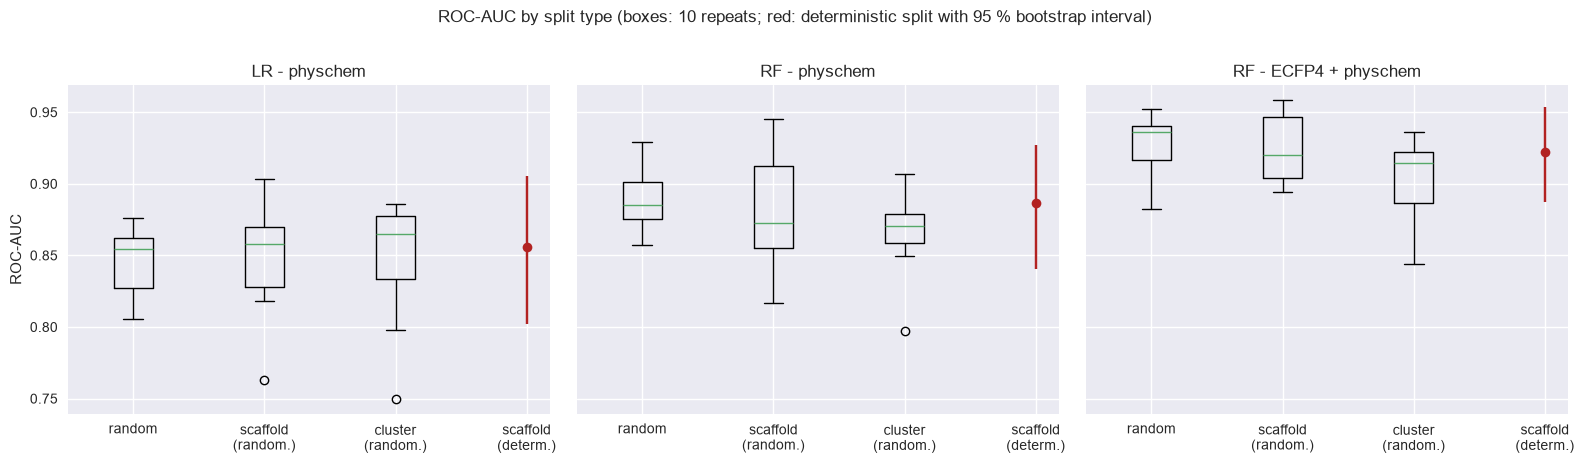

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
rand_splits = split_order[:3]
for ax, model in zip(axes, model_order):
    data = [res[(res["split"] == s) & (res["model"] == model)]["roc_auc"] for s in rand_splits]
    ax.boxplot(data)
    row = det_table.loc[model]
    ax.errorbar([4], [row["roc_auc"]], yerr=[[row["roc_auc"] - row["ci_low"]], [row["ci_high"] - row["roc_auc"]]],
                fmt="o", color="firebrick", capsize=4)
    ax.set_xticks(range(1, 5))
    ax.set_xticklabels(["random", "scaffold\n(random.)", "cluster\n(random.)", "scaffold\n(determ.)"])
    ax.set_title(model)
axes[0].set_ylabel("ROC-AUC")
plt.suptitle("ROC-AUC by split type (boxes: 10 repeats; red: deterministic split with 95 % bootstrap interval)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_split_difficulty.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** If ROC-AUC drops clearly for the cluster and deterministic splits while the nearest-neighbour
similarity also drops, those splits measure generalisation to new chemistry better than the random split. If scores stay
high, the descriptors carry the signal across chemical families. Either result is informative. The tuning and error
analysis below use the harder splits as the outer test sets.

## 6. Nested tuning, threshold and calibration

Outer test sets: the deterministic scaffold split plus `N_OUTER_CLUSTER` randomised cluster splits. For every outer split:

1. **Inner tuning** on the training part only, with 5-fold `GroupKFold` (groups = scaffolds for the scaffold split,
   clusters for the cluster splits). Random forest and XGBoost each have a small grid; the pooled out-of-fold ROC-AUC picks
   the best setting. The better of the two tuned models is the *selected* model.
2. **Threshold:** chosen on the out-of-fold predictions of the selected model to maximise balanced accuracy, instead of
   using 0.5.
3. **Calibration:** a Platt scaling (logistic regression on the logit of the out-of-fold probabilities), also fitted on
   training data only. The Brier score before and after calibration shows whether probabilities become more reliable.
   ROC-AUC does not change under calibration.
4. Evaluation on the outer test set, compared with the untuned defaults from notebook 02.

In [16]:
N_OUTER_CLUSTER = 3

RF_DEFAULT = {"max_features": "sqrt", "min_samples_leaf": 2}
XGB_DEFAULT = {"max_depth": 4, "learning_rate": 0.1, "min_child_weight": 1}

RF_GRID = [{"max_features": mf, "min_samples_leaf": leaf} for mf in ["sqrt", 0.05, 0.15] for leaf in [1, 3]]
XGB_GRID = [{"max_depth": d, "learning_rate": lr, "min_child_weight": mcw}
            for d in [3, 5] for lr in [0.05, 0.1] for mcw in [1, 5]]


def rf_factory(params):
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE, **params)


def xgb_factory(params, pos_weight):
    return XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.5, scale_pos_weight=pos_weight,
                         eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE, **params)


def oof_proba(factory, X, y_, groups, n_splits=5):
    oof = np.zeros(len(y_))
    for tr, va in GroupKFold(n_splits=n_splits).split(X, y_, groups):
        model = factory()
        model.fit(X[tr], y_[tr])
        oof[va] = model.predict_proba(X[va])[:, 1]
    return oof


def best_threshold(y_true, proba):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [balanced_accuracy_score(y_true, (proba >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))])


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p)).reshape(-1, 1)

In [17]:
outer_splits = [("scaffold (deterministic)", det_tr, det_te, scaffold_codes)]
for s in range(N_OUTER_CLUSTER):
    tr_, te_ = randomised_group_split(cluster_groups, s)
    outer_splits.append((f"cluster (randomised) #{s}", tr_, te_, cluster_codes))

nested_rows = []
reliability = {}

for outer_name, tr, te, codes in outer_splits:
    t0 = time.time()
    X_tr, X_te, y_tr, y_te = X_comb[tr], X_comb[te], y[tr], y[te]
    groups_tr = codes[tr]
    pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

    # 1) inner grid search on the training part only
    best = {}
    for model_type, grid, factory in [("RF", RF_GRID, rf_factory),
                                      ("XGB", XGB_GRID, lambda p: xgb_factory(p, pos_weight))]:
        inner = []
        for params in grid:
            oof = oof_proba(lambda: factory(params), X_tr, y_tr, groups_tr)
            inner.append((roc_auc_score(y_tr, oof), params, oof))
        best[model_type] = max(inner, key=lambda item: item[0])

    selected = max(best, key=lambda k: best[k][0])

    # 2) fit defaults and tuned models on the full training part, predict the outer test set
    probas = {
        "RF default": rf_factory(RF_DEFAULT).fit(X_tr, y_tr).predict_proba(X_te)[:, 1],
        "XGB default": xgb_factory(XGB_DEFAULT, pos_weight).fit(X_tr, y_tr).predict_proba(X_te)[:, 1],
        "RF tuned": rf_factory(best["RF"][1]).fit(X_tr, y_tr).predict_proba(X_te)[:, 1],
        "XGB tuned": xgb_factory(best["XGB"][1], pos_weight).fit(X_tr, y_tr).predict_proba(X_te)[:, 1],
    }
    sel_proba = probas[f"{selected} tuned"]
    sel_oof = best[selected][2]

    # 3) threshold and calibration from training data only
    threshold = best_threshold(y_tr, sel_oof)
    calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(logit(sel_oof), y_tr)
    cal_proba = calibrator.predict_proba(logit(sel_proba))[:, 1]

    row = {"outer_split": outer_name, "n_train": len(tr), "n_test": len(te),
           "selected": selected,
           "inner_auc_RF": best["RF"][0], "inner_auc_XGB": best["XGB"][0],
           "params_RF": json.dumps(best["RF"][1]), "params_XGB": json.dumps(best["XGB"][1])}
    for name, p in probas.items():
        row[f"auc_{name.replace(' ', '_')}"] = roc_auc_score(y_te, p)
    row["auc_selected_tuned"] = roc_auc_score(y_te, sel_proba)
    row["bal_acc_at_0.5"] = balanced_accuracy_score(y_te, (sel_proba >= 0.5).astype(int))
    row["threshold"] = threshold
    row["bal_acc_at_threshold"] = balanced_accuracy_score(y_te, (sel_proba >= threshold).astype(int))
    row["brier_raw"] = brier_score_loss(y_te, sel_proba)
    row["brier_calibrated"] = brier_score_loss(y_te, cal_proba)
    nested_rows.append(row)

    if outer_name.startswith("scaffold"):
        reliability = {"y": y_te, "raw": sel_proba, "cal": cal_proba, "model": selected}

    print(f"{outer_name}: selected {selected}, inner AUC RF {best['RF'][0]:.3f} / XGB {best['XGB'][0]:.3f}, "
          f"test AUC {row['auc_selected_tuned']:.3f} ({time.time() - t0:.0f} s)")

nested = pd.DataFrame(nested_rows)
nested.to_csv(RESULTS_DIR / "03_nested_tuning.csv", index=False)
nested[["outer_split", "selected", "inner_auc_RF", "inner_auc_XGB", "auc_RF_default", "auc_RF_tuned",
        "auc_XGB_default", "auc_XGB_tuned", "auc_selected_tuned"]].round(3)

scaffold (deterministic): selected RF, inner AUC RF 0.903 / XGB 0.893, test AUC 0.910 (61 s)
cluster (randomised) #0: selected RF, inner AUC RF 0.901 / XGB 0.888, test AUC 0.919 (61 s)
cluster (randomised) #1: selected RF, inner AUC RF 0.899 / XGB 0.889, test AUC 0.886 (62 s)
cluster (randomised) #2: selected RF, inner AUC RF 0.901 / XGB 0.888, test AUC 0.908 (62 s)


,outer_split,selected,inner_auc_RF,inner_auc_XGB,auc_RF_default,auc_RF_tuned,auc_XGB_default,auc_XGB_tuned,auc_selected_tuned
0,scaffold (deterministic),RF,0.903,0.893,0.922,0.910,0.918,0.918,0.910
1,cluster (randomised) #0,RF,0.901,0.888,0.923,0.919,0.911,0.911,0.919
2,cluster (randomised) #1,RF,0.899,0.889,0.881,0.886,0.882,0.878,0.886
3,cluster (randomised) #2,RF,0.901,0.888,0.904,0.908,0.904,0.905,0.908


### Tuning gain, threshold and calibration

In [18]:
gain = pd.DataFrame({
    "outer_split": nested["outer_split"],
    "tuned_selected - RF_default": nested["auc_selected_tuned"] - nested["auc_RF_default"],
    "tuned_selected - XGB_default": nested["auc_selected_tuned"] - nested["auc_XGB_default"],
}).set_index("outer_split")
print("ROC-AUC difference on the outer test sets (positive = tuning helped)")
display(gain.round(3))
print("Mean over the cluster splits:")
display(gain[gain.index.str.startswith("cluster")].agg(["mean", "std"]).round(3))

print("\nThreshold and calibration")
display(nested[["outer_split", "threshold", "bal_acc_at_0.5", "bal_acc_at_threshold",
                "brier_raw", "brier_calibrated"]].round(3))

ROC-AUC difference on the outer test sets (positive = tuning helped)


,tuned_selected - RF_default,tuned_selected - XGB_default
outer_split,,
scaffold (deterministic),-0.012,-0.008
cluster (randomised) #0,-0.004,0.009
cluster (randomised) #1,0.005,0.004
cluster (randomised) #2,0.004,0.004


Mean over the cluster splits:


,tuned_selected - RF_default,tuned_selected - XGB_default
mean,0.002,0.006
std,0.005,0.003



Threshold and calibration


,outer_split,threshold,bal_acc_at_0.5,bal_acc_at_threshold,brier_raw,brier_calibrated
0,scaffold (deterministic),0.76,0.793,0.841,0.091,0.085
1,cluster (randomised) #0,0.77,0.710,0.862,0.102,0.088
2,cluster (randomised) #1,0.77,0.786,0.822,0.110,0.108
3,cluster (randomised) #2,0.81,0.776,0.841,0.102,0.093


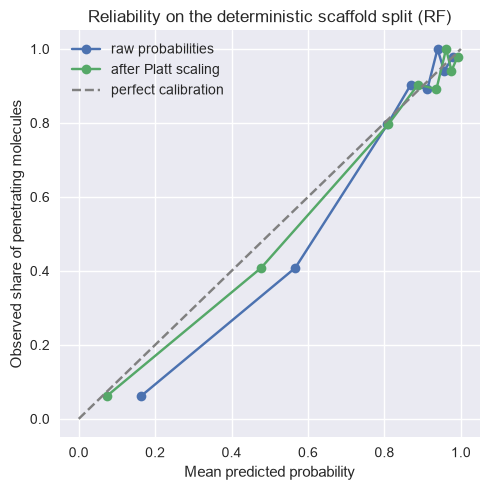

In [19]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(5, 5))
for key, label in [("raw", "raw probabilities"), ("cal", "after Platt scaling")]:
    frac_pos, mean_pred = calibration_curve(reliability["y"], reliability[key], n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed share of penetrating molecules")
ax.set_title(f"Reliability on the deterministic scaffold split ({reliability['model']})")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_reliability.png", dpi=150)
plt.show()

**How to read this:** A tuning gain is only worth reporting if it is positive on all outer splits and clearly larger than
its spread. With three cluster splits, this is a rough guide. A threshold that raises balanced accuracy on the outer test
set shows that the default 0.5 is not optimal for this imbalanced task; if it does not, the threshold choice is not
transferable to new chemistry. A lower Brier score after calibration means more reliable probabilities.

## 7. Error analysis

For the error analysis, every molecule is predicted once by a model that never saw its scaffold family (5-fold
`GroupKFold` on scaffold groups, untuned random forest on ECFP4 + descriptors). Together with the distance to the
training data, this shows **where** the model fails.

In [20]:
oof = np.zeros(n)
nn_oof = np.zeros(n)
for tr, va in GroupKFold(n_splits=5).split(X_comb, y, groups=scaffold_codes):
    model = rf_factory(RF_DEFAULT).fit(X_comb[tr], y[tr])
    oof[va] = model.predict_proba(X_comb[va])[:, 1]
    nn_oof[va] = SIM[np.ix_(va, tr)].max(axis=1)

err = std[["name", "std_smiles", "label"]].copy()
err["scaffold"] = scaffold.values
err["proba"] = oof
err["pred"] = (oof >= 0.5).astype(int)
err["nn_sim"] = nn_oof
err["correct"] = err["pred"] == err["label"]
err["false_neg"] = (err["label"] == 1) & (err["pred"] == 0)
err["false_pos"] = (err["label"] == 0) & (err["pred"] == 1)

print(f"Scaffold-grouped out-of-fold ROC-AUC: {roc_auc_score(y, oof):.3f} | "
      f"balanced accuracy at 0.5: {balanced_accuracy_score(y, err['pred']):.3f} | "
      f"accuracy: {err['correct'].mean():.3f}")

Scaffold-grouped out-of-fold ROC-AUC: 0.918 | balanced accuracy at 0.5: 0.783 | accuracy: 0.876


### By scaffold family

In [21]:
family = (err.groupby("scaffold")
          .agg(n=("label", "size"), positive_rate=("label", "mean"), mean_proba=("proba", "mean"),
               accuracy=("correct", "mean"), false_neg=("false_neg", "sum"), false_pos=("false_pos", "sum")))
family.index = [s if s else "(no ring system)" for s in family.index]

print("The 12 largest scaffold families")
display(family.sort_values("n", ascending=False).head(12).round(2))
print("Hardest families with at least 8 molecules (lowest accuracy)")
hardest = family[family["n"] >= 8].sort_values("accuracy").head(10)
display(hardest.round(2))

family.to_csv(RESULTS_DIR / "03_error_by_family.csv")

The 12 largest scaffold families


,n,positive_rate,mean_proba,accuracy,false_neg,false_pos
c1ccccc1,128,0.72,0.75,0.73,4,30
(no ring system),95,0.93,0.79,0.92,2,6
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21,74,0.96,0.82,0.96,0,3
O=C1CN=C(c2ccccc2)c2ccccc2N1,26,1.00,0.87,1.00,0,0
O=C1C=C2CCC3C4CCCC4CCC3C2CC1,24,0.67,0.75,0.67,0,8
c1ccc2c(c1)Nc1ccccc1S2,22,1.00,0.94,1.00,0,0
c1ccc(Cc2ccccc2)cc1,20,0.95,0.82,0.95,0,1
O=C1CC(=O)NC(=O)N1,18,1.00,0.70,1.00,0,0
O=C(Cc1ccccc1)N1CCNCC1CN1CCCC1,17,0.29,0.67,0.29,0,12
O=C1C=CC2C(=C1)CCC1C2CCC2C1CC1OCOC12,16,1.00,0.89,1.00,0,0


Hardest families with at least 8 molecules (lowest accuracy)


,n,positive_rate,mean_proba,accuracy,false_neg,false_pos
O=C(Cc1ccccc1)N1CCNCC1CN1CCCC1,17,0.29,0.67,0.29,0,12
O=c1cc[nH]cc1,8,0.62,0.76,0.62,0,3
O=C1C=C2CCC3C4CCCC4CCC3C2CC1,24,0.67,0.75,0.67,0,8
c1ccncc1,11,0.64,0.78,0.73,0,3
c1ccccc1,128,0.72,0.75,0.73,4,30
O=c1[nH]c(=O)c2[nH]cnc2[nH]1,8,0.88,0.81,0.88,0,1
C1CCC(OC2CCCC(OC3CCCCO3)C2)OC1,10,0.10,0.15,0.90,1,0
(no ring system),95,0.93,0.79,0.92,2,6
c1ccc(Cc2ccccc2)cc1,20,0.95,0.82,0.95,0,1
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21,74,0.96,0.82,0.96,0,3


### By distance to the training data

In [22]:
err["sim_bin"] = pd.qcut(err["nn_sim"], 5, duplicates="drop")


def bin_auc(g):
    return roc_auc_score(g["label"], g["proba"]) if g["label"].nunique() == 2 else np.nan


by_sim = err.groupby("sim_bin", observed=True).apply(lambda g: pd.Series({
    "n": len(g), "mean_nn_sim": g["nn_sim"].mean(), "positive_rate": g["label"].mean(),
    "accuracy": g["correct"].mean(), "roc_auc": bin_auc(g)}), include_groups=False)
by_sim.index = by_sim.index.astype(str)
by_sim.to_csv(RESULTS_DIR / "03_error_by_similarity.csv")
by_sim.round(3)

,n,mean_nn_sim,positive_rate,accuracy,roc_auc
sim_bin,,,,,
"(0.0466, 0.302]",393.0,0.245,0.768,0.837,0.841
"(0.302, 0.398]",389.0,0.349,0.815,0.841,0.839
"(0.398, 0.506]",391.0,0.452,0.757,0.839,0.908
"(0.506, 0.636]",392.0,0.571,0.753,0.931,0.965
"(0.636, 1.0]",390.0,0.712,0.728,0.933,0.967


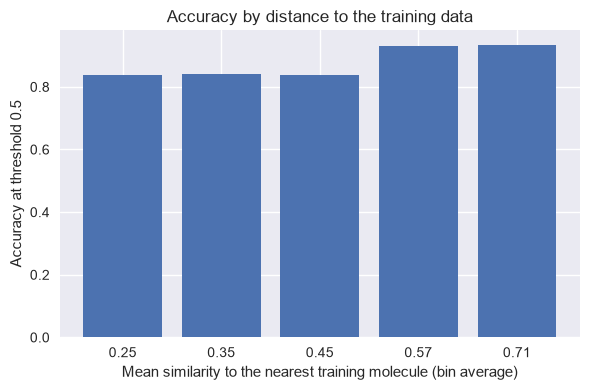

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(len(by_sim)), by_sim["accuracy"], color="#4c72b0")
ax.set_xticks(range(len(by_sim)))
ax.set_xticklabels([f"{v:.2f}" for v in by_sim["mean_nn_sim"]])
ax.set_xlabel("Mean similarity to the nearest training molecule (bin average)")
ax.set_ylabel("Accuracy at threshold 0.5")
ax.set_title("Accuracy by distance to the training data")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_accuracy_by_similarity.png", dpi=150)
plt.show()

### The most confident errors

In [24]:
cols = ["name", "std_smiles", "label", "proba", "nn_sim"]
confident_fn = err[err["false_neg"]].sort_values("proba").head(15)[cols]
confident_fp = err[err["false_pos"]].sort_values("proba", ascending=False).head(15)[cols]

pd.concat([confident_fn.assign(kind="false negative"), confident_fp.assign(kind="false positive")]) \
  .to_csv(RESULTS_DIR / "03_confident_errors.csv", index=False)

print("Penetrating molecules predicted as non-penetrating (lowest probability first)")
display(confident_fn.round(3))
print("Non-penetrating molecules predicted as penetrating (highest probability first)")
display(confident_fp.round(3))

Penetrating molecules predicted as non-penetrating (lowest probability first)


,name,std_smiles,label,proba,nn_sim
5,rolitetracycline,CN(C)[C@@H]1C(=O)/C(=C(/O)NCN2CCCC2)C(=O)[C@@]...,1,0.025,0.863
27,piperacillin,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@@H]2C(=O)N3[C@@H...,1,0.045,0.704
3,cloxacillin,Cc1onc(-c2ccccc2Cl)c1C(=O)N[C@@H]1C(=O)N2[C@@H...,1,0.067,0.562
72,cefuroxime,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)O)=C(COC(N)...,1,0.068,0.628
82,ceftriaxone,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)O)=C(CSc3nc...,1,0.072,0.713
328,Ticarcillin,CC1(C)S[C@@H]2[C@H](NC(=O)[C@H](C(=O)[O-])c3cc...,1,0.073,0.569
45,cefamandole,Cn1nnnc1SCC1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)[C@H...,1,0.081,0.712
348,Ceftazidime,CC(C)(O/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=...,1,0.089,0.659
65,cefotaxime,CO/N=C(\C(=O)N[C@H]1C(=O)N2C(C(=O)[O-])=C(COC(...,1,0.112,0.642
4,cefoperazone,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@@H]2C(=O)N3C(C(=...,1,0.125,0.684


Non-penetrating molecules predicted as penetrating (highest probability first)


,name,std_smiles,label,proba,nn_sim
174,dicyclomine,CCN(CC)CCOC(=O)C1(C2CCCCC2)CCCCC1,0,0.931,0.347
506,Thiopental,CCCC(C)C1(CC)C(=O)NC(=S)NC1=O,0,0.931,0.733
200,Dyclonine,CCCCOc1ccc(C(=O)CCN2CCCCC2)cc1,0,0.928,0.431
178,Domperidone,O=c1[nH]c2ccccc2n1CCCN1CCC(n2c(=O)[nH]c3cc(Cl)...,0,0.911,0.609
170,coumarin,O=c1ccc2ccccc2o1,0,0.909,0.353
663,Efavirenz,O=C1Nc2ccc(Cl)cc2[C@@](C#CC2CC2)(C(F)(F)F)O1,0,0.900,0.309
342,Phenylbutazone,CCCCC1C(=O)N(c2ccccc2)N(c2ccccc2)C1=O,0,0.893,0.366
147,clofibrate,CCOC(=O)C(C)(C)Oc1ccc(Cl)cc1,0,0.891,0.300
771,fenoxazoline,CC(C)c1ccccc1OCC1=NCCN1,0,0.890,0.273
337,phenacetin,CCOc1ccc(NC(C)=O)cc1,0,0.872,0.286


These lists are a starting point for a chemical sanity check: some errors may reflect label noise (the audit found
conflicting duplicates) or special transport mechanisms that fingerprints and simple descriptors cannot capture.

## Findings

1. **Split difficulty (section 5):** The cluster split is the most distant (mean nearest-neighbour similarity 0.391
   vs 0.560 for random), yet ROC-AUC drops only slightly (random forest on ECFP4 + descriptors: 0.928 random, 0.924
   randomised scaffold, 0.905 cluster, 0.922 [0.887, 0.954] deterministic scaffold). The descriptor logistic
   regression does not change at all (0.847 to 0.856). The random forest beats it on every split (+0.081 random,
   +0.075 scaffold, +0.057 cluster; better in 10, 10 and 9 of 10 repeats).
2. **Tuning (section 6):** Nested tuning gives no reliable gain. Random forest won the inner selection in all four outer
   splits; tuned minus default ROC-AUC is -0.012, -0.004, +0.005 and +0.004 for the random forest and between
   -0.004 and +0.002 for XGBoost.
3. **Threshold and calibration:** The training-data threshold (0.76 to 0.81) raises balanced accuracy in all four
   outer splits (0.793 to 0.841, 0.710 to 0.862, 0.786 to 0.822, 0.776 to 0.841). Platt scaling lowers the Brier
   score in all four (for example 0.102 to 0.088).
4. **Error analysis (section 7):** At threshold 0.5 there are 182 false positives and 60 false negatives. Accuracy
   is 0.84 and ROC-AUC 0.84 for molecules with a nearest-neighbour similarity below about 0.5, and 0.93 and 0.97
   above 0.57. Ten of the 15 most confident false negatives are beta-lactam antibiotics whose training neighbours are
   mostly labelled non-penetrating, which points to label inconsistency within the family.

## Limitations

- Grids are small, and tuned gains are measured on only a few outer splits (1 deterministic, `N_OUTER_CLUSTER` clustered).
- The deterministic split is a single split; its interval reflects test-molecule sampling only.
- The Butina cut-off (0.6) is a judgement call, and cluster-based splits depend on it.
- Calibration and threshold are fitted on out-of-fold predictions of models trained on 80 % of the training part, then
  applied to a model trained on all of it.
- The error analysis uses an untuned random forest and one grouping (scaffolds).
- Data and labels come from one dataset with known label noise.

**Next:** `04_graph_neural_network.ipynb` – a GNN under the same harder splits and, if desired, external validation on a
larger blood-brain-barrier dataset.